# **Do crime-prediction models learn policing?**

## Daryna Tkachenko, Machine Learning Advanced (DNDS5019)

____

## 1. Setup and data

- Imports, a fixed random seed and the time periods used throughout the notebook.

- Runs in Google Colab or locally. Models are trained on the CPU.

- The data and the trained parameters are downloaded automatically from the project's GitHub repository. A local copy is used instead if it exists.

- `train_models = False` loads the trained parameters and skips training. `train_models = True` trains every model again and saves new parameters (Section 15).

- Data: CPD crime incidents from 1 Oct 2021 to 1 Oct 2026 (end date exclusive), exported from the City of Chicago Data Portal. Only four columns are kept: date, crime type, arrest flag and community area.

- Rows without a known community area (missing or placeholder 0) are dropped.

In [ ]:
#imports

#data handling
import os
import random
import urllib.request
import numpy as np
import pandas as pd

#plotting
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

#deep models
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

#baseline models
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import mean_absolute_error, mean_poisson_deviance
from scipy.stats import poisson

In [ ]:
#reproducibility
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

#the models are trained on the CPU. My laptop (MacBook Air, 2022) has no NVIDIA graphics card, so CUDA is not available
#the dataset is small (77 areas, about 260 weeks), so the CPU is sufficient
device = torch.device("cpu")
print(f"CUDA: {torch.cuda.is_available()}; "
      f"MPS: {torch.backends.mps.is_available()}; using: {device}")

#sharper plots
plt.rcParams["figure.dpi"] = 120

#data and trained parameters: downloaded from the github repo if there is no local copy
repo_url = "https://raw.githubusercontent.com/darynatk/crime-prediction-policing/main"
data_file = "cpd_crime_2021_2026.csv.gz"
params_file = "trained_params.pt"

def get_file(name):
    #use a local copy if there is one, otherwise download it
    if not os.path.exists(name):
        print(f"downloading {name} ...")
        urllib.request.urlretrieve(f"{repo_url}/{name}", name)
    return name

#train_models = False: load the
#  trained parameters and skip training
#train_models = True: train every model again and save new parameters (section 15)
train_models = False

#tables are saved as plain lists, so the file loads with any pandas version
def pack(table):
    return {"index": table.index.tolist(), "columns": table.columns.tolist(), "data": table.to_numpy().tolist(),
            "names": [table.index.name, table.columns.name]}

def unpack(d):
    table = pd.DataFrame(d["data"], index=d["index"], columns=d["columns"])
    table.index.name, table.columns.name = d["names"]
    return table

if not train_models:
    saved = torch.load(get_file(params_file), weights_only=True)

#time periods (end dates exclusive)
start, end = "2021-10-01", "2026-10-01"
val_start, test_start = "2024-10-01", "2025-10-01"

targets = ["reported", "discovered", "arrests"]

CUDA: False; MPS: False; using: cpu
downloading trained_params.pt ...


In [ ]:
#loading the data
cols = ["Date", "Primary Type", "Arrest", "Community Area"]
df = pd.read_csv(get_file(data_file), usecols=cols, dtype=str)
n_raw = len(df)

#dates and arrest flag
df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y %I:%M:%S %p")
df["Arrest"] = df["Arrest"].str.lower().eq("true")

#drop rows without a known community area (missing or placeholder 0)
df = df[df["Community Area"].notna() & (df["Community Area"] != "0")]
df["Community Area"] = df["Community Area"].astype(int)

#study period - just for robustness
df = df[(df["Date"] >= start) & (df["Date"] < end)].reset_index(drop=True)

print(f"rows loaded: {n_raw:,}")
print(f"after cleaning: {len(df):,}")
print(f"dropped: {n_raw - len(df):,}")

print("\nfirst incident:", df["Date"].min())
print("last incident: ", df["Date"].max())
print("community areas:", df["Community Area"].nunique())

downloading cpd_crime_2021_2026.csv.gz ...
rows loaded: 1,232,113
after cleaning: 1,230,323
dropped: 1,790

first incident: 2021-10-01 00:00:00
last incident:  2026-09-30 23:55:00
community areas: 77


____
## 2. Crime groups

- Each incident is labelled *reported*, *discovered* or *excluded*, based on its crime type (NIBRS categories, see documentation).

- Group sizes and arrest rates, overall and per study year (October to September).

- Monthly arrest rate and number of discovered incidents, and arrest rates and counts per crime type, to check whether the data changes over time.

In [ ]:
society = ["NARCOTICS", "OTHER NARCOTIC VIOLATION", "WEAPONS VIOLATION",
           "CONCEALED CARRY LICENSE VIOLATION", "GAMBLING", "PROSTITUTION", "OBSCENITY"]

persons_property = ["HOMICIDE", "BATTERY", "ASSAULT", "CRIMINAL SEXUAL ASSAULT", "KIDNAPPING",
                    "HUMAN TRAFFICKING", "INTIMIDATION", "STALKING",
                    "THEFT", "BURGLARY", "MOTOR VEHICLE THEFT", "ROBBERY", "CRIMINAL DAMAGE",
                    "DECEPTIVE PRACTICE", "ARSON"]

In [ ]:
#assign each incident to a group based on its crime type
#(types in neither list are excluded from the comparison)
def group_of(primary_type, reported=persons_property, discovered=society):
    if primary_type in reported: return "reported"
    if primary_type in discovered: return "discovered"
    else: return "excluded"

df["group"] = df["Primary Type"].map(group_of)

#group sizes over the whole period:
#number of incidents, share that ended in an arrest, and share of all incidents
summary = df.groupby("group").agg(incidents=("group", "size"), arrest_rate=("Arrest", "mean"))
summary["share"] = summary["incidents"] / summary["incidents"].sum()
display(summary.style.format({"incidents": "{:,}", "arrest_rate": "{:.1%}", "share": "{:.1%}"}))

#technically, in my project fiscal years run from October to September ("Q-SEP" = year ending in September),
#so 2022 stands for Oct 2021 - Sep 2022
study_year = df["Date"].dt.to_period("Q-SEP").dt.qyear #using pandas' offset aliases

#share of each group per study year, to check that the grouping is stable over time
print("Share of incidents per study year:")
by_year = pd.crosstab(study_year, df["group"], normalize="index") #each row sums to 100%
by_year.index = [f"Oct {y - 1} - Sep {y}" for y in by_year.index] # relabel row names
display(by_year.style.format("{:.1%}"))

,incidents,arrest_rate,share
group,,,
discovered,"68,602",79.4%,5.6%
excluded,"128,245",22.4%,10.4%
reported,"1,033,476",8.2%,84.0%


Share of incidents per study year:


group,discovered,excluded,reported
Oct 2021 - Sep 2022,6.1%,10.1%,83.8%
Oct 2022 - Sep 2023,5.4%,9.3%,85.3%
Oct 2023 - Sep 2024,5.5%,10.2%,84.3%
Oct 2024 - Sep 2025,5.7%,11.2%,83.1%
Oct 2025 - Sep 2026,5.1%,11.5%,83.4%


In [ ]:
#arrest rates
arrest_by_year = df.pivot_table(index=study_year, columns="group",
                                values="Arrest", aggfunc="mean")
arrest_by_year.index = [f"Oct {y - 1} - Sep {y}" for y in arrest_by_year.index]
print("Arrest rates:")
display(arrest_by_year.style.format("{:.1%}"))

Arrest rates:


group,discovered,excluded,reported
Oct 2021 - Sep 2022,74.8%,18.4%,6.7%
Oct 2022 - Sep 2023,73.5%,19.9%,6.9%
Oct 2023 - Sep 2024,74.3%,22.6%,8.1%
Oct 2024 - Sep 2025,88.2%,25.6%,9.6%
Oct 2025 - Sep 2026,87.7%,24.7%,9.9%


##### Comparing discovered crime over time

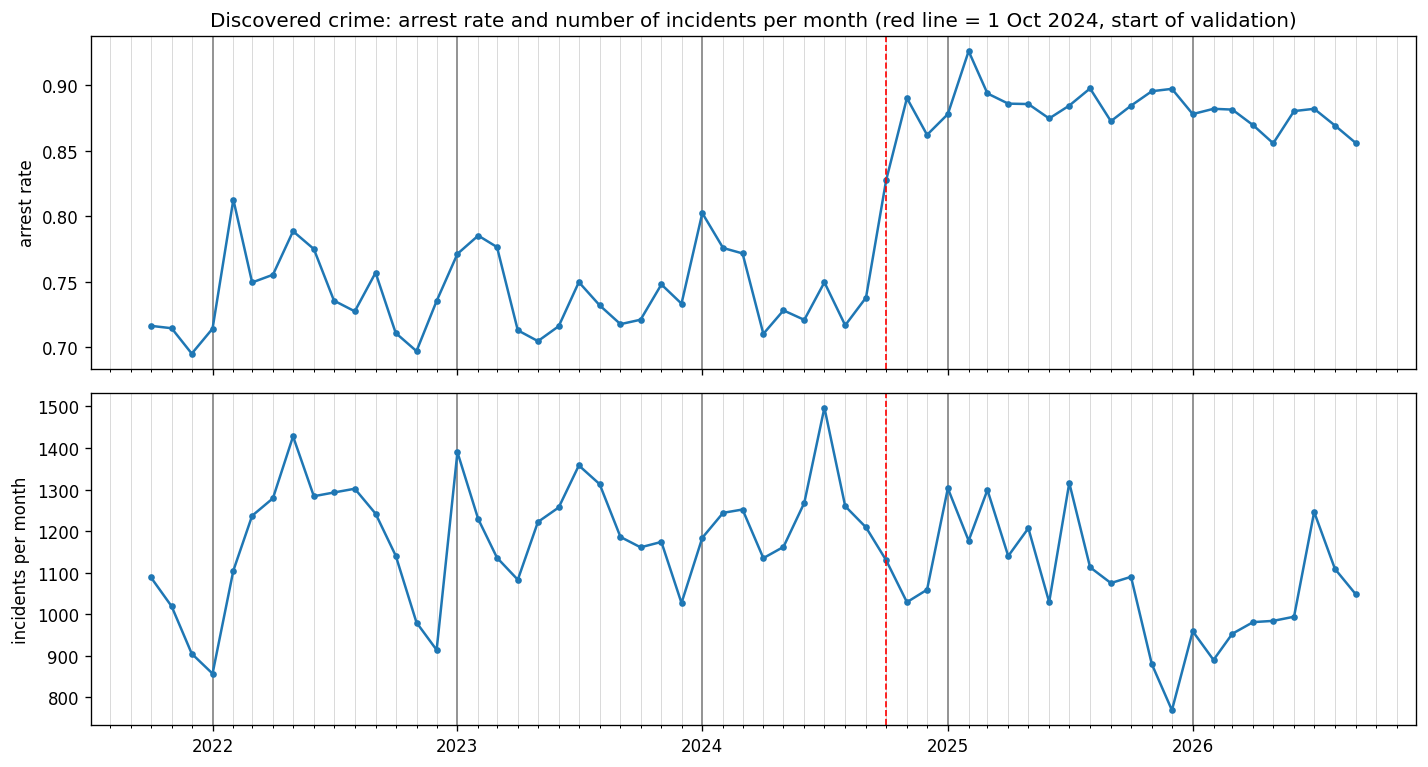

In [ ]:
#keep only discovered crime
disc = df[df["group"] == "discovered"]

#one row per month ("MS" = month start):
#mean of the True/False arrest column = arrest rate, size = number of incidents
monthly = disc.set_index("Date").resample("MS")["Arrest"].agg(["mean", "size"]) #MS - group incidents by month

#two panels sharing the time axis: arrest rate on top, number of incidents below
fig, ax = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
ax[0].plot(monthly.index, monthly["mean"], marker="o", markersize=3)
ax[0].set_ylabel("arrest rate")
ax[1].plot(monthly.index, monthly["size"], marker="o", markersize=3)
ax[1].set_ylabel("incidents per month")

#time axis: dark line and label each January, grey line every month,
#red dashed line where the validation period starts
for a in ax:
    a.xaxis.set_major_locator(mdates.YearLocator())
    a.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    a.xaxis.set_minor_locator(mdates.MonthLocator())
    a.grid(which="minor", axis="x", color="lightgrey", linewidth=0.5)
    a.grid(which="major", axis="x", color="grey", linewidth=1)
    a.axvline(pd.Timestamp("2024-10-01"), color="red", linestyle="--", linewidth=1)

ax[0].set_title("Discovered crime: arrest rate and number of incidents per month "
                "(red line = 1 Oct 2024, start of validation)")
plt.tight_layout(); plt.show()

In [ ]:
#which discovered crime types changed
by_type = disc.pivot_table(index=study_year.loc[disc.index], columns="Primary Type",
                           values="Arrest", aggfunc="mean")
display(by_type.style.format("{:.0%}"))

Primary Type,CONCEALED CARRY LICENSE VIOLATION,GAMBLING,NARCOTICS,OBSCENITY,OTHER NARCOTIC VIOLATION,PROSTITUTION,WEAPONS VIOLATION
Date,,,,,,,
2022,97%,92%,98%,59%,40%,99%,62%
2023,95%,100%,98%,64%,25%,96%,58%
2024,97%,100%,97%,45%,60%,95%,58%
2025,97%,100%,97%,47%,56%,93%,77%
2026,94%,100%,96%,38%,43%,97%,76%


In [ ]:
#number of incidents per crime type and study year
counts_by_type = pd.crosstab(study_year.loc[disc.index], disc["Primary Type"])
display(counts_by_type)

#share of each type within discovered crime (all years together)
display(disc["Primary Type"].value_counts(normalize=True).to_frame("share").style.format("{:.1%}"))

Primary Type,CONCEALED CARRY LICENSE VIOLATION,GAMBLING,NARCOTICS,OBSCENITY,OTHER NARCOTIC VIOLATION,PROSTITUTION,WEAPONS VIOLATION
Date,,,,,,,
2022,172,13,4592,39,5,260,8959
2023,191,11,5119,45,4,238,8601
2024,204,20,5773,56,5,232,8283
2025,269,17,7422,59,9,237,5864
2026,248,16,6504,55,7,151,4922


,share
Primary Type,
WEAPONS VIOLATION,53.4%
NARCOTICS,42.9%
PROSTITUTION,1.6%
CONCEALED CARRY LICENSE VIOLATION,1.6%
OBSCENITY,0.4%
GAMBLING,0.1%
OTHER NARCOTIC VIOLATION,0.0%


____

## 3. Area × week panel

- Function turns the incident list into a grid with one row per community area per week. Each row holds how many reported, discovered and arrest incidents happened in that area that week.

- Weeks run Monday to Sunday; weeks without incidents are zeros.

- Partial weeks at the start and end are dropped.

In [ ]:
def build_panel(df, reported=persons_property, discovered=society):

    d = df.copy()

    #assign each incident to a week
    d["week"] = d["Date"].dt.to_period("W-SUN").dt.start_time

    #the three targets as 0/1 columns, so they can be summed per area and week
    d["reported"] = d["Primary Type"].isin(reported).astype(int)
    d["discovered"] = d["Primary Type"].isin(discovered).astype(int)
    d["arrests"] = d["Arrest"].astype(int) #all arrests, also from excluded crime types

    #count per area and week
    counts = (d.groupby(["Community Area", "week"])[["reported", "discovered", "arrests"]].sum())

    #grid: every area x every week, weeks without incidents = 0
    areas = sorted(d["Community Area"].unique())
    weeks = pd.date_range(d["week"].min(), d["week"].max(), freq="W-MON")
    grid = pd.MultiIndex.from_product([areas, weeks], names=["Community Area", "week"])
    panel = counts.reindex(grid, fill_value=0).reset_index()

    #drop partial weeks at the start and end of the period
    panel = panel[panel["week"] >= pd.Timestamp(start)]
    panel = panel[panel["week"] + pd.Timedelta(days=7) <= pd.Timestamp(end)]

    panel = panel.rename(columns={"Community Area": "area"})
    return panel.sort_values(["area", "week"]).reset_index(drop=True)

panel = build_panel(df)

n_weeks = panel["week"].nunique()
print(f"rows: {len(panel):,} = {panel['area'].nunique()} areas x {n_weeks} weeks")
print(f"weeks: {panel['week'].min().date()} to {panel['week'].max().date()}")
print("missing values:", panel.isna().sum().sum())
print("average per area and week:")
display(panel[["reported", "discovered", "arrests"]].mean().round(1))

rows: 20,020 = 77 areas x 260 weeks
weeks: 2021-10-04 to 2026-09-21
missing values: 0
average per area and week:


,0
reported,51.5
discovered,3.4
arrests,8.4


_____

## 4. Time split

- Train, validation and test are split by week.

    - Train: Oct 2021 - Sep 2024

    - Validation: Oct 2024 - Sep 2025
    
    - Test: Oct 2025 - Sep 2026

In [ ]:
#assign each week to a split based on its start date
panel["split"] = np.where(panel["week"] >= pd.Timestamp(test_start), "test",
                 np.where(panel["week"] >= pd.Timestamp(val_start), "val", "train"))

#weeks and date range per split
split_info = (panel.groupby("split")["week"]
                   .agg(weeks="nunique", first="min", last="max")
                   .loc[["train", "val", "test"]])
display(split_info)

,weeks,first,last
split,,,
train,157,2021-10-04,2024-09-30
val,52,2024-10-07,2025-09-29
test,51,2025-10-06,2026-09-21


_____

## 5. Features and scaling

- Inputs: counts of all three targets in the previous 1-4 weeks (12 lag features), the area, and the week of the year.

- Lags and targets are log-transformed and standardised; the scalers are fitted on training weeks only.

In [ ]:
lags = [1, 2, 3, 4]

#lagged counts, shifted within each area (never across areas)
for t in targets:
    for k in lags:
        panel[f"{t}_lag{k}"] = panel.groupby("area")[t].shift(k)
lag_cols = [f"{t}_lag{k}" for t in targets for k in lags]

#drop the first weeks of each area, which have no full lag history
panel = panel.dropna(subset=lag_cols).reset_index(drop=True)

#area and season inputs
panel["area_id"] = panel["area"] - 1 #areas are numbered 1-77, the embedding needs 0-76
panel["week_of_year"] = panel["week"].dt.isocalendar().week.astype(int) - 1 # 0-52

#season as a point on a circle, so the end of the year meets the start
#a plain 0-52 number would make week 52 and week 0 look far apart
#sine and cosine together give each week a unique position on the circle
panel["week_sin"] = np.sin(2 * np.pi * panel["week_of_year"] / 52)
panel["week_cos"] = np.cos(2 * np.pi * panel["week_of_year"] / 52)

#how different the outputs are in size (training weeks)
train = panel["split"] == "train"
means = panel.loc[train, targets].mean()
print("average per area and week (train):"); display(means.round(1))
print(f"reported / discovered: {means['reported'] / means['discovered']:.1f}x")

#log1p first: counts are skewed (many zeros, a few big weeks), so log squashes the big values
#StandardScaler then centres each column on 0 with spread 1, so the network gets similar-sized inputs
#fitted on training weeks only, so no information from validation or test leaks into training
x_scaler = StandardScaler().fit(np.log1p(panel.loc[train, lag_cols])) #inputs: the 12 lag features
#same idea for the targets; kept separate so predictions can be turned back into real counts later
y_scaler = StandardScaler().fit(np.log1p(panel.loc[train, targets]))

def get_split(name):
    p = panel[panel["split"] == name]
    return {
        "x_num": x_scaler.transform(np.log1p(p[lag_cols])).astype(np.float32), #scaled lag features: the numeric inputs
        "x_area": p["area_id"].to_numpy(), #area ids: used to look up the area vector
        "x_week": p["week_of_year"].to_numpy(), #week of year: used to look up the week vector
        "y": y_scaler.transform(np.log1p(p[targets])).astype(np.float32), #scaled targets: what the model learns to predict
        "y_raw": p[targets].to_numpy()} #real counts: used for the metrics

data = {name: get_split(name) for name in ["train", "val", "test"]}

for name, s in data.items():
    print(f"{name}: x_num {s['x_num'].shape}, y {s['y'].shape}")
print("scaled train targets, mean:", data["train"]["y"].mean(axis=0).round(2),
      "std:", data["train"]["y"].std(axis=0).round(2))

average per area and week (train):


,0
reported,53.1
discovered,3.6
arrests,7.8


reported / discovered: 14.9x
train: x_num (11781, 12), y (11781, 3)
val: x_num (4004, 12), y (4004, 3)
test: x_num (3927, 12), y (3927, 3)
scaled train targets, mean: [ 0. -0. -0.] std: [1. 1. 1.]


____

## 6. Baseline: Poisson regression

- One Poisson regression per target on raw counts.

- Inputs: the 12 scaled lag features, the area (one-hot) and the season (sine/cosine of the week).

- The regularisation strength is chosen on the validation year.

- For the test year the model is refitted on training and validation data, like the deep models.

In [ ]:
def baseline_inputs(name):
    p = panel[panel["split"] == name]
    area_onehot = np.eye(77)[p["area_id"]] #one column per area
    season = p[["week_sin", "week_cos"]].to_numpy()
    return np.hstack([data[name]["x_num"], area_onehot, season])

X = {name: baseline_inputs(name) for name in ["train", "val", "test"]}
alphas = [1e-4, 1e-3, 1e-2, 1e-1, 1]

baseline_pred = {"val": {}, "test": {}}
best_alpha = {}

for i, t in enumerate(targets):
    #pick alpha by poisson deviance on the validation year
    scores = {}
    for a in alphas:
        m = PoissonRegressor(alpha=a, max_iter=1000).fit(X["train"], data["train"]["y_raw"][:, i])
        scores[a] = mean_poisson_deviance(data["val"]["y_raw"][:, i], m.predict(X["val"]))
    best_alpha[t] = min(scores, key=scores.get)

    #validation predictions from the model trained on train only
    m = PoissonRegressor(alpha=best_alpha[t], max_iter=1000).fit(X["train"], data["train"]["y_raw"][:, i])
    baseline_pred["val"][t] = m.predict(X["val"])

    #test predictions from the model refitted on train + validation (same as the deep models)
    X_trval = np.vstack([X["train"], X["val"]])
    y_trval = np.concatenate([data["train"]["y_raw"][:, i], data["val"]["y_raw"][:, i]])
    m = PoissonRegressor(alpha=best_alpha[t], max_iter=1000).fit(X_trval, y_trval)
    baseline_pred["test"][t] = m.predict(X["test"])

print("best alpha per target:", best_alpha)
for t in targets:
    print(f"{t}: mean predicted {baseline_pred['test'][t].mean():.1f} "
          f"vs actual {data['test']['y_raw'][:, targets.index(t)].mean():.1f} (test)")

best alpha per target: {'reported': 0.001, 'discovered': 0.01, 'arrests': 0.1}
reported: mean predicted 49.7 vs actual 48.1 (test)
discovered: mean predicted 3.1 vs actual 3.0 (test)
arrests: mean predicted 8.5 vs actual 9.0 (test)


_____

## 7. Deep model 1: MLP with temporal embeddings

- One network with three outputs (reported, discovered, arrests).

- Inputs: the 12 scaled lag features, plus learned embeddings for the area and the week of the year.

- Trained with MSE on the scaled targets and Adam. With early stopping.

- The training and prediction functions are reused for the LSTM.

In [ ]:
class MLP(nn.Module):
    def __init__(self, n_num, n_areas=77, n_weeks=53, d_area=8, d_week=4,
                 hidden=64, n_layers=2, dropout=0.1, n_out=3):
        super().__init__()
        #learned embeddings: one vector per area and per week of the year
        self.area_emb = nn.Embedding(n_areas, d_area)
        self.week_emb = nn.Embedding(n_weeks, d_week)

        #hidden layers: linear -> relu -> dropout, repeated n_layers times
        layers = []
        size_in = n_num + d_area + d_week
        for _ in range(n_layers):
            layers += [nn.Linear(size_in, hidden), nn.ReLU(), nn.Dropout(dropout)]
            size_in = hidden
        self.hidden = nn.Sequential(*layers)

        #one output per target
        self.out = nn.Linear(hidden, n_out)

    def forward(self, x_num, x_area, x_week):
        x = torch.cat([x_num, self.area_emb(x_area), self.week_emb(x_week)], dim=1)
        return self.out(self.hidden(x))

In [ ]:
#@title Training and prediction functions (shared by both deep models)
def make_loader(s, batch_size=256, shuffle=False):
    ds = TensorDataset(torch.tensor(s["x_num"]),
                       torch.tensor(s["x_area"], dtype=torch.long),
                       torch.tensor(s["x_week"], dtype=torch.long),
                       torch.tensor(s["y"]))
    #fixed generator, so the shuffling is the same every run
    gen = torch.Generator().manual_seed(seed)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, generator=gen)


@torch.no_grad()
def eval_loss(model, loader, loss_fn):
    model.eval()
    total = 0
    for *inputs, y in loader:
        inputs = [x.to(device) for x in inputs]
        total += loss_fn(model(*inputs), y.to(device)).item() * len(y)
    return total / len(loader.dataset)


def train_model(model, train_loader, val_loader, lr=1e-3, max_epochs=200, patience=15):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    history = {"train": [], "val": []}
    best_val, best_state, wait = float("inf"), None, 0

    for epoch in range(max_epochs):
        model.train()
        total = 0
        for *inputs, y in train_loader:
            inputs = [x.to(device) for x in inputs]
            y = y.to(device)
            opt.zero_grad()
            loss = loss_fn(model(*inputs), y)
            loss.backward()
            opt.step()
            total += loss.item() * len(y)
        history["train"].append(total / len(train_loader.dataset))

        #early stopping: keep the weights with the lowest validation loss
        val_loss = eval_loss(model, val_loader, loss_fn)
        history["val"].append(val_loss)
        if val_loss < best_val:
            best_val, wait = val_loss, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state)
    return model, history, best_val


@torch.no_grad()
def predict_counts(model, loader, scaler=None):
    #predictions back to real counts: undo scaling, undo log1p, no negative counts
    #(scaler: y_scaler by default, another one only in the robustness check)
    if scaler is None:
        scaler = y_scaler
    model.eval()
    preds = [model(*[x.to(device) for x in inputs]).cpu().numpy() for *inputs, _ in loader]
    counts = np.expm1(scaler.inverse_transform(np.vstack(preds)))
    return np.clip(counts, 0, None)

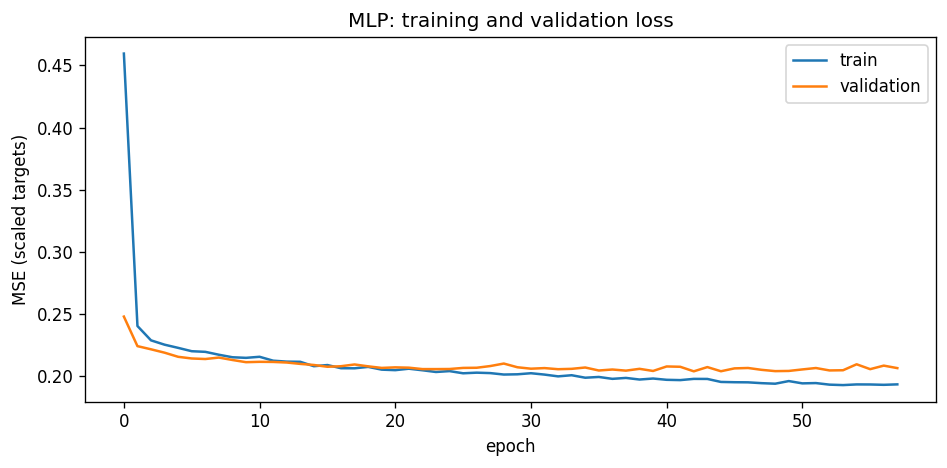

epochs trained: 58 | best validation loss: 0.204
smallest prediction: 0.0
reported: mean predicted 50.7 vs actual 50.2 (validation)
discovered: mean predicted 3.3 vs actual 3.5 (validation)
arrests: mean predicted 8.2 vs actual 9.7 (validation)


In [ ]:
loaders = {"train": make_loader(data["train"], shuffle=True),
           "val": make_loader(data["val"]),
           "test": make_loader(data["test"])}

torch.manual_seed(seed)
mlp = MLP(n_num=len(lag_cols))
if train_models:
    mlp, mlp_history, mlp_best_val = train_model(mlp, loaders["train"], loaders["val"])
else:
    #saved weights and loss history from the training run
    mlp.load_state_dict(saved["mlp_default"])
    mlp_history = saved["mlp_history"]
    mlp_best_val = min(mlp_history["val"])

#training vs validation loss
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mlp_history["train"], label="train")
ax.plot(mlp_history["val"], label="validation")
ax.set_xlabel("epoch"); ax.set_ylabel("MSE (scaled targets)")
ax.set_title("MLP: training and validation loss")
ax.legend(); plt.tight_layout(); plt.show()

print(f"epochs trained: {len(mlp_history['val'])} | best validation loss: {mlp_best_val:.3f}")

#checkpoint: predictions in real counts on the validation year
mlp_val_pred = predict_counts(mlp, loaders["val"])
print("smallest prediction:", mlp_val_pred.min().round(2))
for i, t in enumerate(targets):
    print(f"{t}: mean predicted {mlp_val_pred[:, i].mean():.1f} "
          f"vs actual {data['val']['y_raw'][:, i].mean():.1f} (validation)")

_____

## 8. Deep model 2: LSTM

- Reads the last L weeks of each area as a sequence, instead of hand-made lag features.

- Each week in the sequence: the three scaled log counts and the season (sine/cosine of the week).

- The area embedding is added after the LSTM, before the output layer. Same three outputs as the MLP.

- Same loss, optimiser and early stopping as the MLP, so the comparison is fair.

In [ ]:
#@title Sequences for the LSTM
seq_features = targets + ["week_sin", "week_cos"] #5 values per week

def make_sequences(panel, L=12, scaler=None):
    if scaler is None:
        scaler = y_scaler
    p = panel.copy()
    #same scaling as the targets: log1p, then the y_scaler fitted on training weeks
    p[targets] = scaler.transform(np.log1p(p[targets]))

    x_seq, x_area, y, y_raw, split = [], [], [], [], []

    #sequences are built within each area, never across areas
    for area, g in p.groupby("area"):
        feats = g[seq_features].to_numpy(np.float32)
        raw = panel.loc[g.index, targets].to_numpy()

        #target week t, history = the L weeks before it (may come from an earlier split)
        for t in range(L, len(g)):
            x_seq.append(feats[t - L:t]) #the L weeks before week t: the input
            y.append(feats[t, :3]) #the three scaled counts in week t, the answer
            y_raw.append(raw[t]) #the real counts in week t: for the errors
            x_area.append(g["area_id"].iloc[t])
            split.append(g["split"].iloc[t])  #the target week decides the split

    x_seq = np.array(x_seq)
    x_area = np.array(x_area)
    y = np.array(y)
    y_raw = np.array(y_raw)
    split = np.array(split)

    seq_data = {}
    for name in ["train", "val", "test"]:
        m = split == name
        seq_data[name] = {"x_seq": x_seq[m], "x_area": x_area[m], "y": y[m], "y_raw": y_raw[m]}
    return seq_data

def make_seq_loader(s, batch_size=256, shuffle=False):
    ds = TensorDataset(torch.tensor(s["x_seq"]),
                       torch.tensor(s["x_area"], dtype=torch.long),
                       torch.tensor(s["y"]))
    gen = torch.Generator().manual_seed(seed)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, generator=gen)


L = 12
seq_data = make_sequences(panel, L)
for name, s in seq_data.items():
    print(f"{name}: x_seq {s['x_seq'].shape}, x_area {s['x_area'].shape}, y {s['y'].shape}")

train: x_seq (10857, 12, 5), x_area (10857,), y (10857, 3)
val: x_seq (4004, 12, 5), x_area (4004,), y (4004, 3)
test: x_seq (3927, 12, 5), x_area (3927,), y (3927, 3)


In [ ]:
class LSTMForecaster(nn.Module):
    def __init__(self, n_features=5, hidden=32, n_layers=1, d_area=8, n_areas=77,
                 dropout=0.0, n_out=3):
        super().__init__()
        #dropout between lstm layers only works with 2+ layers
        self.lstm = nn.LSTM(n_features, hidden, num_layers=n_layers, batch_first=True,
                            dropout=dropout if n_layers > 1 else 0.0)
        self.area_emb = nn.Embedding(n_areas, d_area)
        self.out = nn.Linear(hidden + d_area, n_out)

    def forward(self, x_seq, x_area):
        _, (h, _) = self.lstm(x_seq) #h: final hidden state of each layer
        last = h[-1] #final hidden state of the last layer
        return self.out(torch.cat([last, self.area_emb(x_area)], dim=1))

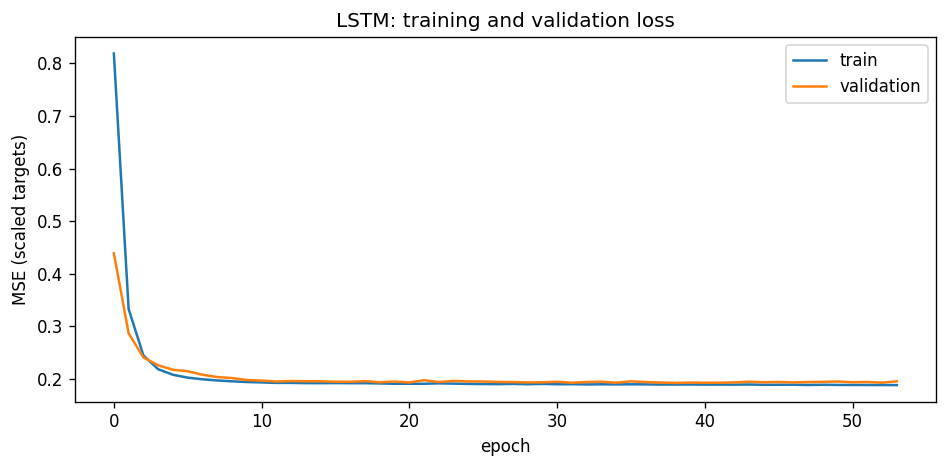

epochs trained: 54 | best validation loss: 0.192
MLP best validation loss for comparison: 0.204
smallest prediction: 0.0
reported: mean predicted 50.8 vs actual 50.2 (validation)
discovered: mean predicted 3.1 vs actual 3.5 (validation)
arrests: mean predicted 8.7 vs actual 9.7 (validation)


In [ ]:
seq_loaders = {"train": make_seq_loader(seq_data["train"], shuffle=True),
               "val": make_seq_loader(seq_data["val"]),
               "test": make_seq_loader(seq_data["test"])}

torch.manual_seed(seed)
lstm = LSTMForecaster()
if train_models:
    lstm, lstm_history, lstm_best_val = train_model(lstm, seq_loaders["train"], seq_loaders["val"])
else:
    lstm.load_state_dict(saved["lstm_default"])
    lstm_history = saved["lstm_history"]
    lstm_best_val = min(lstm_history["val"])

#training vs validation loss
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(lstm_history["train"], label="train")
ax.plot(lstm_history["val"], label="validation")
ax.set_xlabel("epoch"); ax.set_ylabel("MSE (scaled targets)")
ax.set_title("LSTM: training and validation loss")
ax.legend(); plt.tight_layout(); plt.show()

print(f"epochs trained: {len(lstm_history['val'])} | best validation loss: {lstm_best_val:.3f}")
print(f"MLP best validation loss for comparison: {mlp_best_val:.3f}")

#checkpoint: predictions in real counts on the validation year
lstm_val_pred = predict_counts(lstm, seq_loaders["val"])
print("smallest prediction:", lstm_val_pred.min().round(2))
for i, t in enumerate(targets):
    print(f"{t}: mean predicted {lstm_val_pred[:, i].mean():.1f} "
          f"vs actual {seq_data['val']['y_raw'][:, i].mean():.1f} (validation)")

_____

## 9. Hyperparameter tuning (random search)

- Both deep models are tuned the same way: 20 random settings each, picked from small lists of values.

- Each setting is trained on the training weeks with early stopping and judged by its validation loss.

- The best setting is then retrained on training and validation weeks together, for the number of epochs it needed, and predicts the test year once.

In [ ]:
n_trials = 20
rng = random.Random(seed) #own random generator, so the search is the same every run

mlp_space = {"hidden": [16, 32, 64, 128, 256],
             "n_layers": [1, 2, 3],
             "dropout": [0.0, 0.1, 0.2, 0.3, 0.5],
             "lr": [1e-4, 3e-4, 1e-3, 3e-3, 1e-2], #each step about 3 times the previous one
             "d_area": [2, 4, 8, 16],
             "d_week": [2, 4, 8, 16]}

lstm_space = {"hidden": [8, 16, 32, 64, 128],
              "n_layers": [1, 2],
              "L": [4, 8, 12, 18, 26],
              "lr": [1e-4, 3e-4, 1e-3, 3e-3, 1e-2],
              "d_area": [2, 4, 8, 16]}

def sample(space):
    #one random value from each list
    return {k: rng.choice(v) for k, v in space.items()}

In [ ]:
#mlp: random search
if train_models:
    mlp_trials = []
    for i in range(n_trials):
        params = sample(mlp_space)
        torch.manual_seed(seed)
        model = MLP(n_num=len(lag_cols), d_area=params["d_area"], d_week=params["d_week"],
                    hidden=params["hidden"], n_layers=params["n_layers"], dropout=params["dropout"])
        model, history, val_loss = train_model(model, loaders["train"], loaders["val"], lr=params["lr"])

        params["val_loss"] = val_loss
        params["epochs"] = int(np.argmin(history["val"])) + 1 #epoch with the lowest validation loss
        mlp_trials.append(params)
        print(f"mlp {i + 1}/{n_trials}: validation loss {val_loss:.3f}")
else:
    #the 20 settings and their validation losses from the training run
    mlp_trials = saved["mlp_trials"]

best_mlp = min(mlp_trials, key=lambda r: r["val_loss"])

In [ ]:
#lstm: random search (sequences are rebuilt for each window length L, once)
if train_models:
    seq_by_L = {}
    lstm_trials = []
    for i in range(n_trials):
        params = sample(lstm_space)
        if params["L"] not in seq_by_L:
            seq_by_L[params["L"]] = make_sequences(panel, params["L"])
        s = seq_by_L[params["L"]]

        torch.manual_seed(seed)
        model = LSTMForecaster(hidden=params["hidden"], n_layers=params["n_layers"], d_area=params["d_area"])
        model, history, val_loss = train_model(model, make_seq_loader(s["train"], shuffle=True),
                                               make_seq_loader(s["val"]), lr=params["lr"])

        params["val_loss"] = val_loss
        params["epochs"] = int(np.argmin(history["val"])) + 1
        lstm_trials.append(params)
        print(f"lstm {i + 1}/{n_trials}: validation loss {val_loss:.3f}")
else:
    lstm_trials = saved["lstm_trials"]

best_lstm = min(lstm_trials, key=lambda r: r["val_loss"])

if not train_models:
    #only the window length of the best setting is needed
    seq_by_L = {best_lstm["L"]: make_sequences(panel, best_lstm["L"])}

,hidden,n_layers,dropout,lr,d_area,d_week,val_loss,epochs,L
mlp,32,2,0.0,0.0001,16,2.0,0.202663,170,NaN
lstm,64,1,NaN,0.0003,16,NaN,0.188562,60,26.0


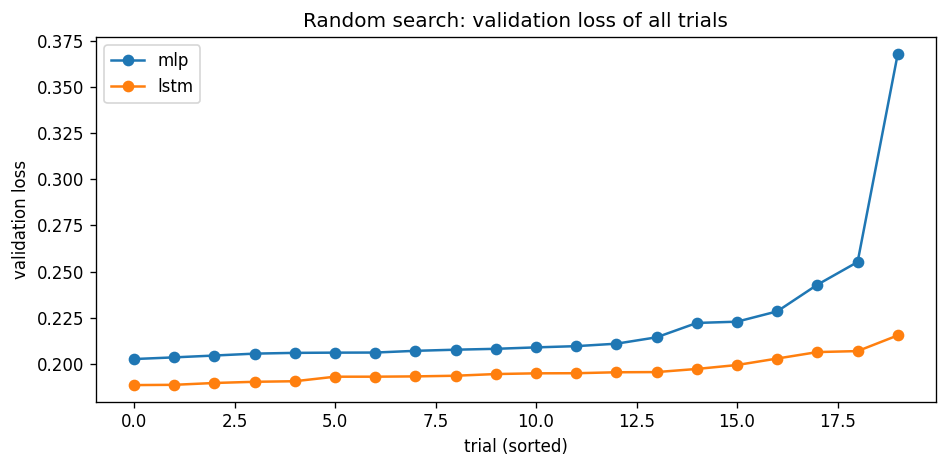

In [ ]:
#best settings of both models
display(pd.DataFrame([best_mlp, best_lstm], index=["mlp", "lstm"]))

#all trials, to see how much the settings matter
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sorted(r["val_loss"] for r in mlp_trials), marker="o", label="mlp")
ax.plot(sorted(r["val_loss"] for r in lstm_trials), marker="o", label="lstm")
ax.set_xlabel("trial (sorted)"); ax.set_ylabel("validation loss")
ax.set_title("Random search: validation loss of all trials")
ax.legend(); plt.tight_layout(); plt.show()

In [ ]:
def train_fixed(model, loader, lr, epochs, loss_fn=None):
    #train for a fixed number of epochs (no validation weeks left for early stopping)
    #(loss_fn: MSE by default, another one only in section 13.5)
    if loss_fn is None:
        loss_fn = nn.MSELoss()
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        model.train()
        for *inputs, y in loader:
            inputs = [x.to(device) for x in inputs]
            opt.zero_grad()
            loss = loss_fn(model(*inputs), y.to(device))
            loss.backward()
            opt.step()
    return model

def combine(a, b):
    #stack training and validation rows
    return {k: np.concatenate([a[k], b[k]]) for k in a}

#final mlp: best setting, retrained on train + validation, predicts the test year once
torch.manual_seed(seed)
mlp_final = MLP(n_num=len(lag_cols), d_area=best_mlp["d_area"], d_week=best_mlp["d_week"],
                hidden=best_mlp["hidden"], n_layers=best_mlp["n_layers"], dropout=best_mlp["dropout"])
if train_models:
    mlp_final = train_fixed(mlp_final, make_loader(combine(data["train"], data["val"]), shuffle=True),
                            best_mlp["lr"], best_mlp["epochs"])
else:
    mlp_final.load_state_dict(saved["mlp_final"])
mlp_test_pred = predict_counts(mlp_final, loaders["test"])

#final lstm: same procedure
best_seq = seq_by_L[best_lstm["L"]]
torch.manual_seed(seed)
lstm_final = LSTMForecaster(hidden=best_lstm["hidden"], n_layers=best_lstm["n_layers"],
                            d_area=best_lstm["d_area"])
if train_models:
    lstm_final = train_fixed(lstm_final, make_seq_loader(combine(best_seq["train"], best_seq["val"]), shuffle=True),
                             best_lstm["lr"], best_lstm["epochs"])
else:
    lstm_final.load_state_dict(saved["lstm_final"])
lstm_test_pred = predict_counts(lstm_final, make_seq_loader(best_seq["test"]))

#the best deep model is chosen on validation loss, not on the test year
best_deep = "mlp" if best_mlp["val_loss"] <= best_lstm["val_loss"] else "lstm"
print("best deep model (validation):", best_deep)

best deep model (validation): lstm


_____

## 10. Evaluation on the test year

- All three models are compared on the test year (Oct 2025 - Sep 2026), separately for each target.

- MAE and Poisson deviance are computed on real counts.

- Scaled MAE is the MAE divided by the target's average, so targets of different sizes can be compared.

- Skill is the improvement over the baseline for the same target: 0 means as good as the baseline, 0.1 means 10% lower error.

In [ ]:
y_test = data["test"]["y_raw"]

#the lstm rows must be the same area-weeks in the same order as for the other models
assert (best_seq["test"]["y_raw"] == y_test).all()

preds = {"baseline": np.column_stack([baseline_pred["test"][t] for t in targets]),
         "mlp": mlp_test_pred,
         "lstm": lstm_test_pred}

rows = []
for model_name, pred in preds.items():
    for i, t in enumerate(targets):
        mae = mean_absolute_error(y_test[:, i], pred[:, i])
        dev = mean_poisson_deviance(y_test[:, i], np.clip(pred[:, i], 1e-6, None)) #needs predictions > 0
        rows.append({"model": model_name, "target": t, "mae": mae, "deviance": dev,
                     "scaled_mae": mae / y_test[:, i].mean()})
results = pd.DataFrame(rows)

#skill: improvement over the baseline for the same target
base = results[results["model"] == "baseline"].set_index("target")
results["mae_skill"] = 1 - results["mae"] / results["target"].map(base["mae"])
results["deviance_skill"] = 1 - results["deviance"] / results["target"].map(base["deviance"])

display(results.set_index(["model", "target"]).style.format("{:.3f}"))

In [ ]:
#the two numbers that matter most, as model x target tables
print("scaled MAE (lower = better):")
display(results.pivot(index="model", columns="target", values="scaled_mae")[targets].style.format("{:.3f}"))
print("MAE skill over the baseline (higher = better):")
display(results.pivot(index="model", columns="target", values="mae_skill")[targets].style.format("{:.3f}"))

scaled MAE (lower = better):


target,reported,discovered,arrests
model,,,
baseline,0.143,0.468,0.284
lstm,0.143,0.452,0.276
mlp,0.147,0.453,0.287


MAE skill over the baseline (higher = better):


target,reported,discovered,arrests
model,,,
baseline,0.000,0.000,0.000
lstm,-0.001,0.034,0.027
mlp,-0.026,0.033,-0.010


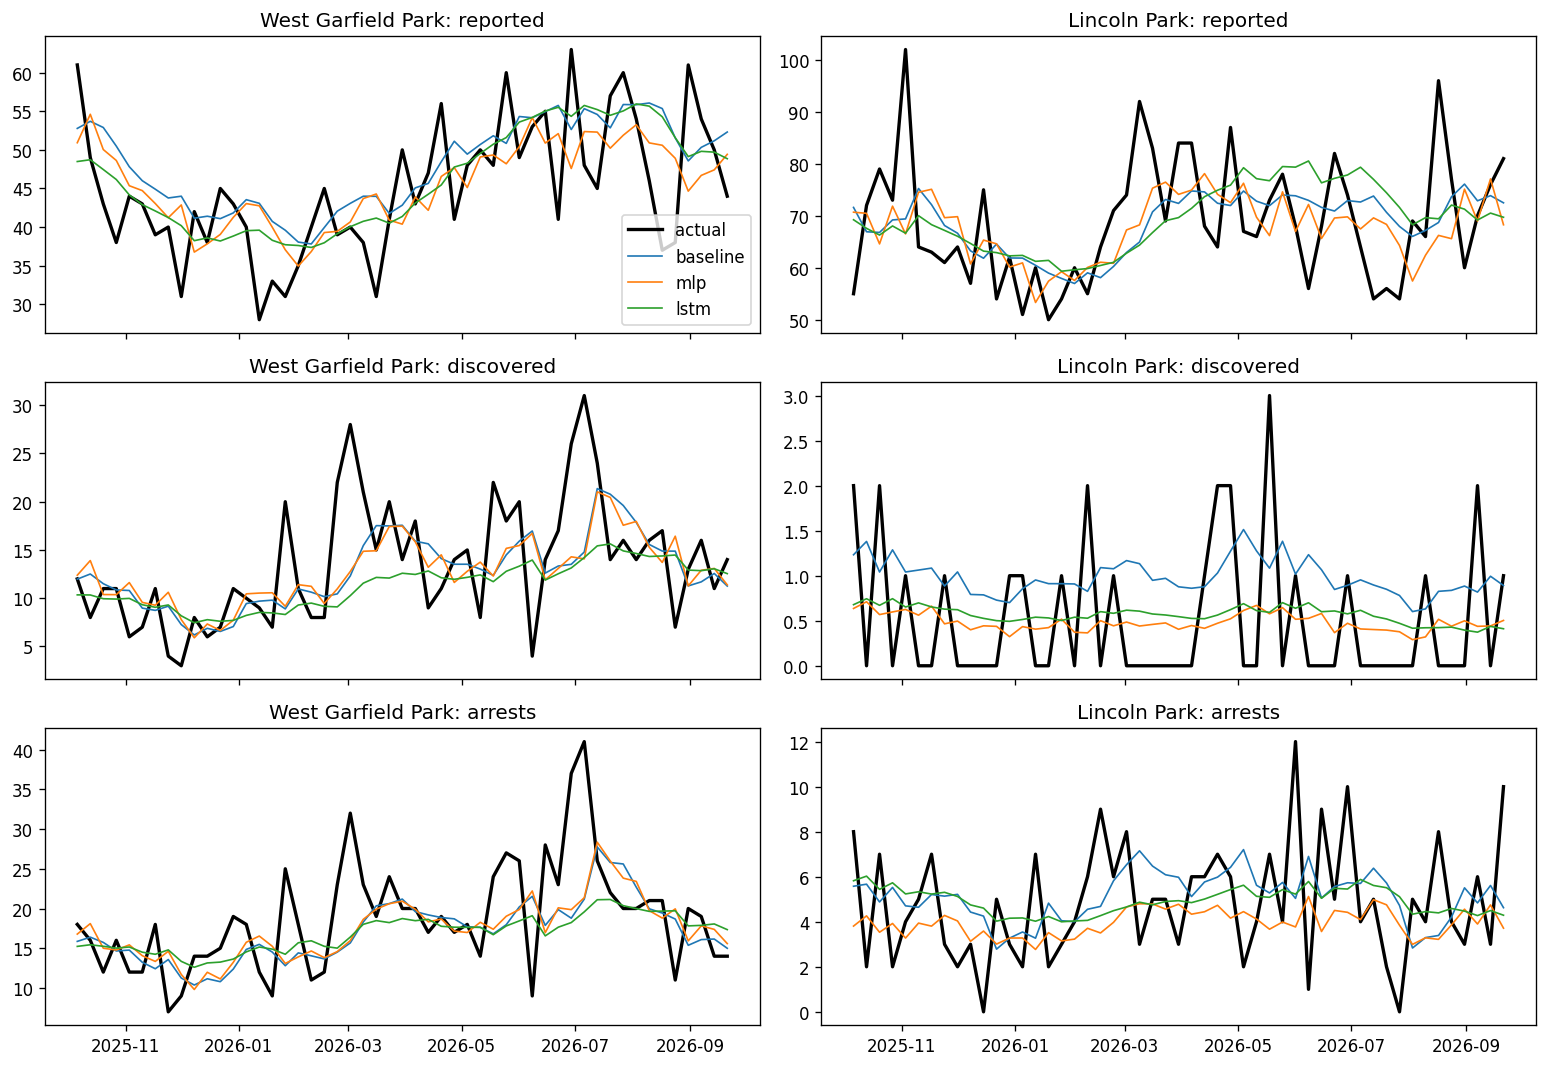

In [ ]:
#actual vs predicted weekly counts in two contrasting areas
test_rows = panel[panel["split"] == "test"].reset_index(drop=True)
areas_to_plot = {26: "West Garfield Park", 7: "Lincoln Park"}

fig, ax = plt.subplots(3, 2, figsize=(13, 9), sharex=True)
for col, (area, name) in enumerate(areas_to_plot.items()):
    m = (test_rows["area"] == area).to_numpy()
    weeks = test_rows.loc[m, "week"]
    for row, t in enumerate(targets):
        a = ax[row, col]
        a.plot(weeks, y_test[m, row], color="black", linewidth=2, label="actual")
        for model_name, pred in preds.items():
            a.plot(weeks, pred[m, row], linewidth=1, label=model_name)
        a.set_title(f"{name}: {t}")
ax[0, 0].legend()
plt.tight_layout(); plt.show()

_____

## 11. Interpretation with SHAP (H1, H2)

- SHAP splits each prediction into contributions from the inputs. Done for the final MLP and LSTM, on 1,000 test rows, with 500 training rows as background.

- Inputs are grouped into three blocks: past counts, season and area. For each target, the table shows each block's share of the total contribution.

- The embeddings are turned into plain numbers first, because SHAP needs inputs it can take gradients of.

In [ ]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")
try:
    import shap
except ImportError: #shap is not installed in every environment (e.g. colab)
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap"], check=True)
    import shap

np_rng = np.random.default_rng(seed)
n_test = len(data["test"]["y"])
bg_idx = np_rng.choice(len(data["train"]["y"]), 500, replace=False) #background rows
ex_idx = np_rng.choice(n_test, min(1000, n_test), replace=False) #rows to explain

def shap_values(model, background, x):
    #shap values with shape (rows, inputs..., targets)
    sv = shap.GradientExplainer(model, background).shap_values(x)
    if isinstance(sv, list): #older shap versions return one array per target
        sv = np.stack(sv, axis=-1)
    return np.asarray(sv)

def block_shares(blocks):
    #mean |shap| per block and target, as a share of the total per target
    table = pd.DataFrame(blocks, index=targets).T
    return table / table.sum()

In [ ]:
#mlp: the embeddings as plain numbers, in the same order as in MLP.forward
class MLPOnFloats(nn.Module):
    def __init__(self, mlp):
        super().__init__()
        self.mlp = mlp
    def forward(self, x):
        return self.mlp.out(self.mlp.hidden(x))

@torch.no_grad()
def mlp_floats(s, idx):
    return torch.cat([torch.tensor(s["x_num"][idx]),
                      mlp_final.area_emb(torch.tensor(s["x_area"][idx], dtype=torch.long)),
                      mlp_final.week_emb(torch.tensor(s["x_week"][idx], dtype=torch.long))], dim=1)

mlp_final.eval()
sv = shap_values(MLPOnFloats(mlp_final), mlp_floats(data["train"], bg_idx), mlp_floats(data["test"], ex_idx))
imp = np.abs(sv).mean(axis=0) #(inputs, targets)

n_lag, d_a = len(lag_cols), best_mlp["d_area"]
mlp_shares = block_shares({"past counts": imp[:n_lag].sum(axis=0),
                           "area": imp[n_lag:n_lag + d_a].sum(axis=0),
                           "season": imp[n_lag + d_a:].sum(axis=0)})
print("MLP: share of each input block per target")
display(mlp_shares.style.format("{:.1%}"))

MLP: share of each input block per target


,reported,discovered,arrests
past counts,69.5%,56.7%,68.6%
area,29.0%,41.1%,29.7%
season,1.5%,2.2%,1.8%


In [ ]:
#lstm: the area embedding is added as extra channels to the sequence (read from the first week only)
class LSTMOnFloats(nn.Module):
    def __init__(self, lstm, n_features=5):
        super().__init__()
        self.lstm = lstm
        self.n = n_features
    def forward(self, x):
        _, (h, _) = self.lstm.lstm(x[:, :, :self.n])
        area = x[:, 0, self.n:]
        return self.lstm.out(torch.cat([h[-1], area], dim=1))

@torch.no_grad()
def lstm_floats(s, idx):
    seq = torch.tensor(s["x_seq"][idx])
    area = lstm_final.area_emb(torch.tensor(s["x_area"][idx], dtype=torch.long))
    area = area.unsqueeze(1).repeat(1, seq.shape[1], 1) #same area vector at every week
    return torch.cat([seq, area], dim=2)

lstm_final.eval()
bg_idx_l = np_rng.choice(len(best_seq["train"]["y"]), 500, replace=False)
sv = shap_values(LSTMOnFloats(lstm_final), lstm_floats(best_seq["train"], bg_idx_l),
                 lstm_floats(best_seq["test"], ex_idx))
imp = np.abs(sv).mean(axis=0).sum(axis=0) #summed over the weeks: (channels, targets)

#channels: 0-2 = scaled counts of the three targets, 3-4 = sine/cosine of the week, 5+ = area
lstm_shares = block_shares({"past counts": imp[:3].sum(axis=0),
                            "area": imp[5:].sum(axis=0),
                            "season": imp[3:5].sum(axis=0)})
print("LSTM: share of each input block per target")
display(lstm_shares.style.format("{:.1%}"))

LSTM: share of each input block per target


,reported,discovered,arrests
past counts,88.3%,85.0%,88.2%
area,2.5%,8.0%,4.9%
season,9.1%,7.1%,6.9%


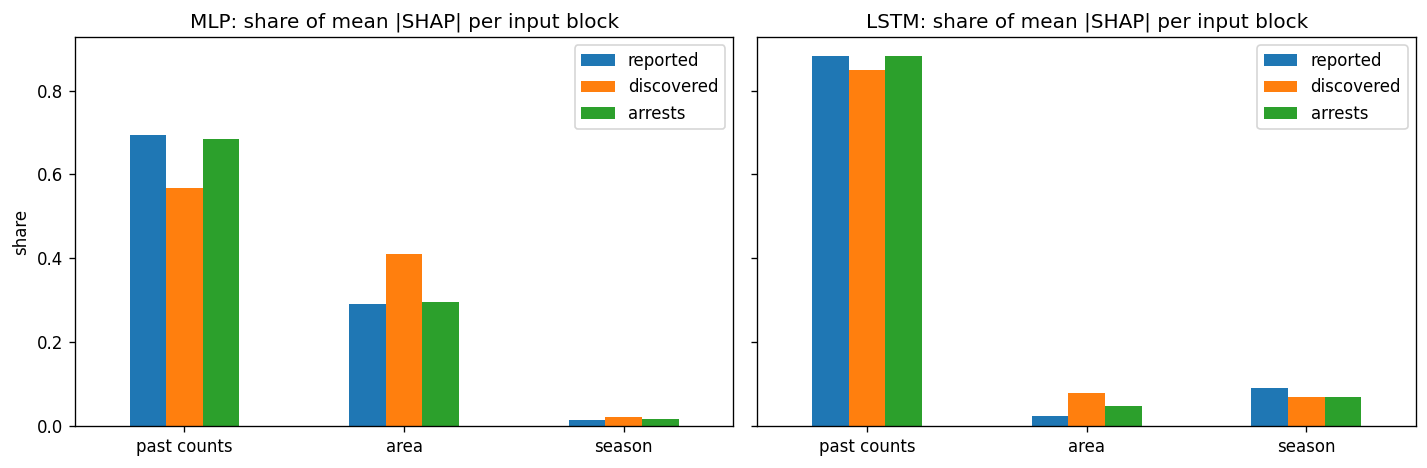

In [ ]:
#grouped bar chart: input blocks x targets, one panel per model
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, (name, shares) in zip(ax, [("MLP", mlp_shares), ("LSTM", lstm_shares)]):
    shares.plot.bar(ax=a, rot=0)
    a.set_title(f"{name}: share of mean |SHAP| per input block")
    a.set_ylabel("share")
plt.tight_layout(); plt.show()

_____

## 12. Robustness: alternative crime groupings

- Two other definitions of discovered crime: only drug and weapon offenses (narrowed), or with the Group B offenses added (widened).

- For each, the whole pipeline is run again: panel, split, lags, scaling, baseline, and the best deep model with its tuned settings (no new tuning).

- Checked: does the comparison between reported and discovered crime stay the same?

In [ ]:
#@title Robustness: rerun the pipeline for each grouping
group_b = ["INTERFERENCE WITH PUBLIC OFFICER", "PUBLIC PEACE VIOLATION",
           "LIQUOR LAW VIOLATION", "CRIMINAL TRESPASS"]
variants = {
    "main":     (persons_property, society),
    "narrowed": (persons_property, ["NARCOTICS", "OTHER NARCOTIC VIOLATION",
                                    "WEAPONS VIOLATION", "CONCEALED CARRY LICENSE VIOLATION"]),
    "widened":  (persons_property, society + group_b),
}

def run_variant(reported, discovered):
    #same steps as sections 3-6 and 9, for another grouping
    p = build_panel(df, reported, discovered)
    p["split"] = "train"
    p.loc[p["week"] >= pd.Timestamp(val_start), "split"] = "val"
    p.loc[p["week"] >= pd.Timestamp(test_start), "split"] = "test"
    for t in targets:
        for k in lags:
            p[f"{t}_lag{k}"] = p.groupby("area")[t].shift(k)
    p = p.dropna(subset=lag_cols).reset_index(drop=True)
    p["area_id"] = p["area"] - 1
    p["week_of_year"] = p["week"].dt.isocalendar().week.astype(int) - 1
    p["week_sin"] = np.sin(2 * np.pi * p["week_of_year"] / 52)
    p["week_cos"] = np.cos(2 * np.pi * p["week_of_year"] / 52)

    tr = p["split"] == "train"
    xs = StandardScaler().fit(np.log1p(p.loc[tr, lag_cols]))
    ys = StandardScaler().fit(np.log1p(p.loc[tr, targets]))
    d = {}
    for name in ["train", "val", "test"]:
        q = p[p["split"] == name]
        d[name] = {"x_num": xs.transform(np.log1p(q[lag_cols])).astype(np.float32),
                   "x_area": q["area_id"].to_numpy(),
                   "x_week": q["week_of_year"].to_numpy(),
                   "y": ys.transform(np.log1p(q[targets])).astype(np.float32),
                   "y_raw": q[targets].to_numpy(),
                   "base_x": np.hstack([xs.transform(np.log1p(q[lag_cols])),
                                        np.eye(77)[q["area_id"]],
                                        q[["week_sin", "week_cos"]].to_numpy()])}
    trval = combine(d["train"], d["val"])
    y_true = d["test"]["y_raw"]

    #baseline: same alphas as in section 6, fitted on train + validation
    base_pred = np.column_stack([
        PoissonRegressor(alpha=best_alpha[t], max_iter=1000)
        .fit(trval["base_x"], trval["y_raw"][:, i]).predict(d["test"]["base_x"])
        for i, t in enumerate(targets)])

    #best deep model with its tuned settings, retrained on train + validation
    torch.manual_seed(seed)
    if best_deep == "mlp":
        b = best_mlp
        model = MLP(n_num=len(lag_cols), d_area=b["d_area"], d_week=b["d_week"],
                    hidden=b["hidden"], n_layers=b["n_layers"], dropout=b["dropout"])
        model = train_fixed(model, make_loader(trval, shuffle=True), b["lr"], b["epochs"])
        deep_pred = predict_counts(model, make_loader(d["test"]), scaler=ys)
    else:
        b = best_lstm
        s = make_sequences(p, b["L"], scaler=ys)
        model = LSTMForecaster(hidden=b["hidden"], n_layers=b["n_layers"], d_area=b["d_area"])
        model = train_fixed(model, make_seq_loader(combine(s["train"], s["val"]), shuffle=True),
                            b["lr"], b["epochs"])
        deep_pred = predict_counts(model, make_seq_loader(s["test"]), scaler=ys)

    out = {}
    for i, t in enumerate(targets):
        mae_base = mean_absolute_error(y_true[:, i], base_pred[:, i])
        mae_deep = mean_absolute_error(y_true[:, i], deep_pred[:, i])
        out[f"{t}: scaled MAE"] = mae_deep / y_true[:, i].mean()
        out[f"{t}: skill"] = 1 - mae_deep / mae_base
    return out

if train_models:
    robust = pd.DataFrame({name: run_variant(*lists) for name, lists in variants.items()}).T
else:
    #retrains the deep model three times, so the saved results are loaded instead
    robust = unpack(saved["robust"])
display(robust.style.format("{:.3f}"))

,reported: scaled MAE,reported: skill,discovered: scaled MAE,discovered: skill,arrests: scaled MAE,arrests: skill
main,0.143,-0.001,0.452,0.034,0.276,0.027
narrowed,0.143,-0.001,0.455,0.034,0.276,0.027
widened,0.142,0.012,0.353,0.017,0.274,0.034


_____

## 13. Post-hoc analyses

- Exploratory checks, not part of the project plan. They were added after the results of sections 10-12, so they are reported separately from the planned confirmatory analysis.

- 13.1-13.2: whether the difference between discovered and reported crime in section 11 reflects location or group size.

- 13.3: how much of the prediction error is random noise in the counts (noise floor).

- 13.4-13.5: two possible improvements, tested briefly: variation across random seeds, and a Poisson loss instead of MSE.

- The planned analysis in sections 1-12 is unchanged. The only code change is an optional loss argument in `train_fixed` (section 9), needed for 13.5; the default is still MSE.

##### 13.1 Area-only model

- Predicts each area's average week from train + validation. No past counts, no season.

- If a target is mostly about *where*, this simple model should be almost as good as the baseline.

In [ ]:
#area-only model: each area's average week in train + validation, nothing else
area_mean = panel[panel["split"] != "test"].groupby("area")[targets].mean()
area_only = area_mean.loc[test_rows["area"]].to_numpy()

rows = []
for i, t in enumerate(targets):
    y = y_test[:, i]
    rows.append({"target": t,
                 "area only": mean_absolute_error(y, area_only[:, i]) / y.mean(),
                 "baseline": mean_absolute_error(y, preds["baseline"][:, i]) / y.mean(),
                 best_deep: mean_absolute_error(y, preds[best_deep][:, i]) / y.mean()})
area_check = pd.DataFrame(rows).set_index("target")

#how much worse the area-only model is than the baseline (0 = area alone is enough)
area_check["extra error without past counts"] = area_check["area only"] / area_check["baseline"] - 1
print("scaled MAE per model, and the extra error of the area-only model:")
display(area_check.style.format("{:.3f}"))

scaled MAE per model, and the extra error of the area-only model:


,area only,baseline,lstm,extra error without past counts
target,,,,
reported,0.177,0.143,0.143,0.242
discovered,0.526,0.468,0.452,0.123
arrests,0.292,0.284,0.276,0.028


##### 13.2 The same check for single crime types

- Reported crime is the sum of about 15 crime types, discovered crime of a few small ones. So the groups differ a lot in size.

- Here the check from 13.1 is repeated for each crime type separately: an area-only model vs a Poisson model with the type's own last 4 weeks, area and season.

- If discovered types still depend less on their past than reported types *of the same size*, the difference is not just about size.

- Types with fewer than 0.2 incidents per area and week are left out (mostly zeros).

In [ ]:
#@title Per crime type: area-only vs Poisson with own history
#weekly counts per area for every crime type, on the same area-weeks as the panel
d = df[["Community Area", "Date", "Primary Type"]].copy()
d["week"] = d["Date"].dt.to_period("W-SUN").dt.start_time
type_counts = d.groupby(["Community Area", "week", "Primary Type"]).size().unstack(fill_value=0)
type_counts.index.names = ["area", "week"]

types = [t for t in persons_property + society if t in type_counts.columns]
series = panel[["area", "week", "split", "area_id", "week_sin", "week_cos"] + targets].join(
    type_counts[types], on=["area", "week"]).fillna(0)

def area_vs_history(s, col):
    #area-only model vs a poisson model that also has the last 4 weeks
    s = s[["area", "split", "area_id", "week_sin", "week_cos", col]].copy()
    for k in lags:
        s[f"lag{k}"] = s.groupby("area")[col].shift(k)
    s = s.dropna()
    fit, test = s["split"] != "test", s["split"] == "test"
    y = s.loc[test, col]

    #area only: the area's average week in train + validation
    area_only = s.loc[test, "area"].map(s[fit].groupby("area")[col].mean())

    #poisson: own last 4 weeks + area + season, same inputs as the baseline but for one series
    lag_x = np.log1p(s[[f"lag{k}" for k in lags]])
    lag_x = StandardScaler().fit(lag_x[fit]).transform(lag_x)
    X = np.hstack([lag_x, np.eye(77)[s["area_id"]], s[["week_sin", "week_cos"]].to_numpy()])
    pred = PoissonRegressor(alpha=1e-3, max_iter=1000).fit(X[fit], s.loc[fit, col]).predict(X[test])

    return {"mean per area-week": s.loc[fit, col].mean(),
            "extra error without past counts": mean_absolute_error(y, area_only) / mean_absolute_error(y, pred) - 1}

rows = []
for col in targets + types:
    if col in targets:
        group = col
    elif col in persons_property:
        group = "reported type"
    else:
        group = "discovered type"
    res = area_vs_history(series, col)
    if res["mean per area-week"] >= 0.2:
        rows.append({"series": col, "group": group, **res})

size_check = pd.DataFrame(rows).sort_values("mean per area-week").reset_index(drop=True)
display(size_check.style.format({"mean per area-week": "{:.2f}",
                                 "extra error without past counts": "{:+.1%}"}).hide(axis="index"))

series,group,mean per area-week,extra error without past counts
CRIMINAL SEXUAL ASSAULT,reported type,0.41,-3.0%
NARCOTICS,discovered type,1.45,+9.4%
WEAPONS VIOLATION,discovered type,1.96,+24.4%
BURGLARY,reported type,2.03,+10.8%
ROBBERY,reported type,2.24,+34.9%
discovered,discovered,3.55,+12.1%
DECEPTIVE PRACTICE,reported type,4.19,+6.7%
ASSAULT,reported type,5.53,+3.8%
MOTOR VEHICLE THEFT,reported type,5.59,+12.4%
CRIMINAL DAMAGE,reported type,6.98,+6.3%


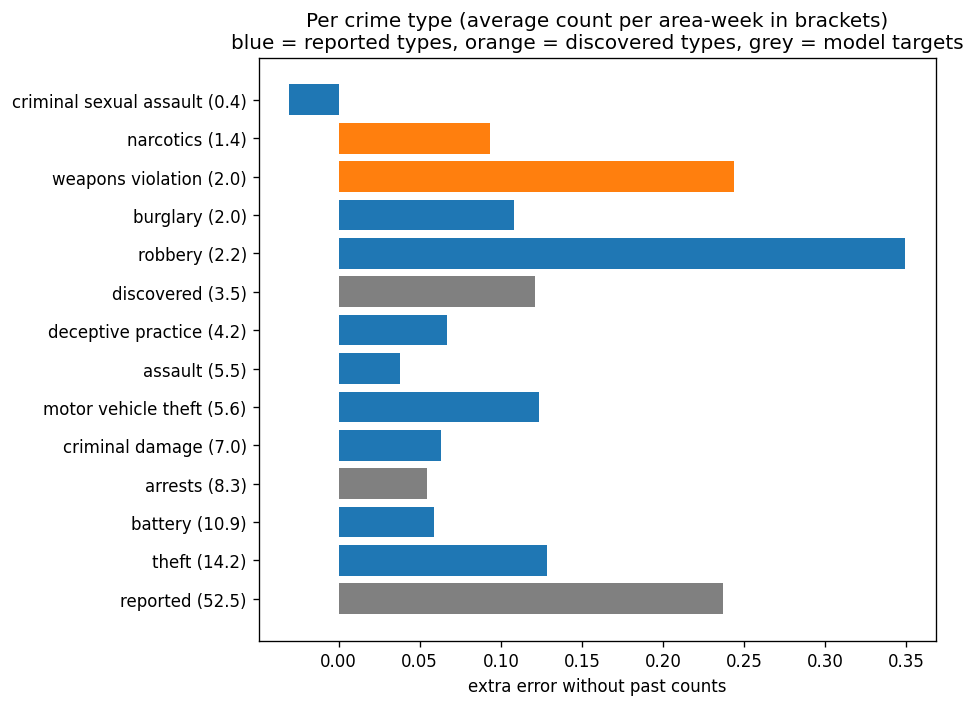

In [ ]:
#one bar per crime type, smallest at the top; the three model targets in grey
colors = {"reported type": "tab:blue", "discovered type": "tab:orange"}
bar_colors = [colors.get(g, "grey") for g in size_check["group"]]
labels = [f"{s.lower()} ({m:.1f})" for s, m in zip(size_check["series"], size_check["mean per area-week"])]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(labels, size_check["extra error without past counts"], color=bar_colors)
ax.invert_yaxis()
ax.set_xlabel("extra error without past counts")
ax.set_title("Per crime type (average count per area-week in brackets)\n"
             "blue = reported types, orange = discovered types, grey = model targets")
plt.tight_layout(); plt.show()

##### 13.3 Noise floor

- Weekly counts are partly random. Even a perfect model would still make some error.

- If the counts were Poisson noise around the predicted mean, this is the smallest scaled MAE possible. Small counts (discovered crime) have a much higher floor than large ones.

- "left to gain" = how much lower the error could get at most, if the predicted means were right.

In [ ]:
#expected MAE if counts were poisson noise around the model's predicted mean
lam = np.clip(preds[best_deep], 1e-6, None)
rows = []
for i, t in enumerate(targets):
    k = np.arange(0, int(y_test[:, i].max()) + 50) #possible counts
    expected_mae = (np.abs(k - lam[:, [i]]) * poisson.pmf(k, lam[:, [i]])).sum(axis=1).mean()
    y = y_test[:, i]
    rows.append({"target": t,
                 "noise floor": expected_mae / y.mean(),
                 best_deep: mean_absolute_error(y, preds[best_deep][:, i]) / y.mean()})
floor_check = pd.DataFrame(rows).set_index("target")
floor_check["left to gain"] = 1 - floor_check["noise floor"] / floor_check[best_deep]
print("scaled MAE: noise floor vs the best deep model")
display(floor_check.style.format("{:.3f}"))

scaled MAE: noise floor vs the best deep model


,noise floor,lstm,left to gain
target,,,
reported,0.107,0.143,0.248
discovered,0.369,0.452,0.185
arrests,0.234,0.276,0.153


##### 13.4 Different random seeds

- The final deep model is retrained 5 times with the same settings, only the seed for the starting weights changes.

- Shows how much the skill over the baseline moves between runs. Differences smaller than this are not meaningful.

In [ ]:
#the best deep model, its data and its loader function, so the code below works for both models
if best_deep == "mlp":
    best_params, best_data, loader_fn = best_mlp, data, make_loader
else:
    best_params, best_data, loader_fn = best_lstm, best_seq, make_seq_loader

def new_best_model():
    #fresh, untrained copy of the best deep model with its tuned settings
    b = best_params
    if best_deep == "mlp":
        return MLP(n_num=len(lag_cols), d_area=b["d_area"], d_week=b["d_week"],
                   hidden=b["hidden"], n_layers=b["n_layers"], dropout=b["dropout"])
    return LSTMForecaster(hidden=b["hidden"], n_layers=b["n_layers"], d_area=b["d_area"])

trval_loader = loader_fn(combine(best_data["train"], best_data["val"]), shuffle=True)
base_mae = results[results["model"] == "baseline"].set_index("target")["mae"]

if train_models:
    rows = []
    for s in range(5):
        torch.manual_seed(s) #only the starting weights change, the batch order stays the same
        model = train_fixed(new_best_model(), trval_loader, best_params["lr"], best_params["epochs"])
        pred = predict_counts(model, loader_fn(best_data["test"]))
        for i, t in enumerate(targets):
            rows.append({"seed": s, "target": t,
                         "skill": 1 - mean_absolute_error(y_test[:, i], pred[:, i]) / base_mae[t]})

    seed_check = pd.DataFrame(rows).pivot(index="seed", columns="target", values="skill")[targets]
else:
    seed_check = unpack(saved["seed_check"])
print(f"MAE skill of the {best_deep} over the baseline, 5 seeds:")
display(seed_check.agg(["mean", "std", "min", "max"]).style.format("{:.3f}"))

MAE skill of the lstm over the baseline, 5 seeds:


target,reported,discovered,arrests
mean,0.007,0.039,0.026
std,0.013,0.005,0.004
min,-0.009,0.031,0.021
max,0.025,0.044,0.030


##### 13.5 Poisson loss instead of MSE

- The deep models were trained with MSE on log-scaled counts. For small counts with many zeros, a count loss might fit better.

- Same model and settings as before, but the outputs are log counts and the loss is Poisson (`nn.PoissonNLLLoss`). The inputs stay the same.

- The settings were tuned for MSE, not for this loss, so this is only a rough check.

- Expected: the biggest change for discovered crime, which has the smallest counts.

In [ ]:
def raw_targets(s):
    #same rows, but the real counts as targets (needed for the poisson loss)
    return {**s, "y": s["y_raw"].astype(np.float32)}

if train_models:
    torch.manual_seed(seed)
    model = train_fixed(new_best_model(), loader_fn(raw_targets(combine(best_data["train"], best_data["val"])), shuffle=True),
                        best_params["lr"], best_params["epochs"], loss_fn=nn.PoissonNLLLoss(log_input=True))

    #outputs are log counts now, so exp gives the predicted counts
    model.eval()
    with torch.no_grad():
        out = [model(*inputs) for *inputs, _ in loader_fn(raw_targets(best_data["test"]))]
    poisson_pred = torch.exp(torch.cat(out)).numpy()

    rows = []
    for i, t in enumerate(targets):
        y = y_test[:, i]
        mae_mse = mean_absolute_error(y, preds[best_deep][:, i])
        mae_poisson = mean_absolute_error(y, poisson_pred[:, i])
        rows.append({"target": t, "MSE loss": mae_mse / y.mean(), "Poisson loss": mae_poisson / y.mean(),
                     "skill of Poisson over MSE": 1 - mae_poisson / mae_mse})
    loss_check = pd.DataFrame(rows).set_index("target")
else:
    loss_check = unpack(saved["loss_check"])
print(f"scaled MAE of the {best_deep}, trained with each loss:")
display(loss_check.style.format("{:.3f}"))

scaled MAE of the lstm, trained with each loss:


,MSE loss,Poisson loss,skill of Poisson over MSE
target,,,
reported,0.143,0.141,0.010
discovered,0.452,0.489,-0.081
arrests,0.276,0.276,0.003


_____

## 14. Results summary

- One table with the numbers each hypothesis is checked on. The interpretation is in the documentation.

- The rows marked "post-hoc" come from section 13. They were not planned in advance.

In [ ]:
#@title Summary table
#discovered types vs reported types of similar size (up to twice the largest discovered type)
disc_types = size_check[size_check["group"] == "discovered type"]
similar_rep = size_check[(size_check["group"] == "reported type") &
                         (size_check["mean per area-week"] <= 2 * disc_types["mean per area-week"].max())]

best = results[results["model"] == best_deep].set_index("target")
shares = mlp_shares if best_deep == "mlp" else lstm_shares

#main hypothesis, part 2: is discovered crime closer to arrests than to reported crime
#(distance between the SHAP block shares)
def dist(a, b):
    return np.linalg.norm(shares[a] - shares[b])

summary_table = pd.DataFrame([
    {"question": "main: discovered predicted differently from reported",
     "checked on": f"scaled MAE ({best_deep}): reported vs discovered",
     "values": f"{best.loc['reported', 'scaled_mae']:.3f} vs {best.loc['discovered', 'scaled_mae']:.3f}",
     "supported": "see values"},
    {"question": "main: discovered behaves more like arrests",
     "checked on": "SHAP shares: distance discovered-arrests vs discovered-reported",
     "values": f"{dist('discovered', 'arrests'):.3f} vs {dist('discovered', 'reported'):.3f}",
     "supported": dist("discovered", "arrests") < dist("discovered", "reported")},
    {"question": "H1: past counts predict discovered better than reported",
     "checked on": "SHAP share of past counts: discovered vs reported",
     "values": f"{shares.loc['past counts', 'discovered']:.1%} vs {shares.loc['past counts', 'reported']:.1%}",
     "supported": shares.loc["past counts", "discovered"] > shares.loc["past counts", "reported"]},
    {"question": "H2: season matters more for reported",
     "checked on": "SHAP share of season: reported vs discovered",
     "values": f"{shares.loc['season', 'reported']:.1%} vs {shares.loc['season', 'discovered']:.1%}",
     "supported": shares.loc["season", "reported"] > shares.loc["season", "discovered"]},
    {"question": "deep models vs baseline",
     "checked on": f"MAE skill of {best_deep}: reported / discovered / arrests",
     "values": " / ".join(f"{best.loc[t, 'mae_skill']:.3f}" for t in targets),
     "supported": "see values"},
    {"question": "robustness: same ordering under other groupings",
     "checked on": "scaled MAE discovered vs reported in all three groupings",
     "values": " / ".join(f"{r['discovered: scaled MAE']:.3f} vs {r['reported: scaled MAE']:.3f}"
                          for _, r in robust.iterrows()),
     "supported": len({r["discovered: scaled MAE"] > r["reported: scaled MAE"] for _, r in robust.iterrows()}) == 1},
    {"question": "post-hoc: area alone is enough for discovered",
     "checked on": "extra error of the area-only model: discovered vs reported (13.1)",
     "values": f"{area_check.loc['discovered', 'extra error without past counts']:+.1%} vs "
               f"{area_check.loc['reported', 'extra error without past counts']:+.1%}",
     "supported": area_check.loc["discovered", "extra error without past counts"]
                  < area_check.loc["reported", "extra error without past counts"]},
    {"question": "post-hoc: same for single crime types of similar size",
     "checked on": "extra error, discovered types vs reported types up to twice their size (13.2)",
     "values": f"{disc_types['extra error without past counts'].mean():+.1%} vs "
               f"{similar_rep['extra error without past counts'].mean():+.1%}",
     "supported": "see values and plot"},
    {"question": "post-hoc: room left above the noise floor",
     "checked on": "left to gain: reported / discovered / arrests (13.3)",
     "values": " / ".join(f"{floor_check.loc[t, 'left to gain']:.1%}" for t in targets),
     "supported": "see values"},
    {"question": "post-hoc: skill over baseline larger than seed noise",
     "checked on": "skill mean ± std over 5 seeds: reported / discovered / arrests (13.4)",
     "values": " / ".join(f"{seed_check[t].mean():.3f} ± {seed_check[t].std():.3f}" for t in targets),
     "supported": "see values"},
    {"question": "post-hoc: Poisson loss helps",
     "checked on": "skill of Poisson over MSE loss: reported / discovered / arrests (13.5)",
     "values": " / ".join(f"{loss_check.loc[t, 'skill of Poisson over MSE']:.3f}" for t in targets),
     "supported": "see values"},
])
display(summary_table.style.hide(axis="index"))

question,checked on,values,supported
main: discovered predicted differently from reported,scaled MAE (lstm): reported vs discovered,0.143 vs 0.452,see values
main: discovered behaves more like arrests,SHAP shares: distance discovered-arrests vs discovered-reported,0.045 vs 0.067,True
H1: past counts predict discovered better than reported,SHAP share of past counts: discovered vs reported,85.0% vs 88.3%,False
H2: season matters more for reported,SHAP share of season: reported vs discovered,9.1% vs 7.1%,True
deep models vs baseline,MAE skill of lstm: reported / discovered / arrests,-0.001 / 0.034 / 0.027,see values
robustness: same ordering under other groupings,scaled MAE discovered vs reported in all three groupings,0.452 vs 0.143 / 0.455 vs 0.143 / 0.353 vs 0.142,True
post-hoc: area alone is enough for discovered,extra error of the area-only model: discovered vs reported (13.1),+12.3% vs +24.2%,True
post-hoc: same for single crime types of similar size,"extra error, discovered types vs reported types up to twice their size (13.2)",+16.9% vs +14.2%,see values and plot
post-hoc: room left above the noise floor,left to gain: reported / discovered / arrests (13.3),24.8% / 18.5% / 15.3%,see values
post-hoc: skill over baseline larger than seed noise,skill mean ± std over 5 seeds: reported / discovered / arrests (13.4),0.007 ± 0.013 / 0.039 ± 0.005 / 0.026 ± 0.004,see values


_____

## 15. Saving the trained parameters

- Runs only when `train_models = True`. Saves the weights of the four deep models, the random-search results and the results of the checks that retrain models (Sections 12, 13.4, 13.5).

- With `train_models = False`, the notebook loads this file instead of training (downloaded from the GitHub repository).

In [ ]:
if train_models:
    torch.save({"mlp_default": mlp.state_dict(), "mlp_history": mlp_history,
                "lstm_default": lstm.state_dict(), "lstm_history": lstm_history,
                "mlp_trials": mlp_trials, "lstm_trials": lstm_trials,
                "mlp_final": mlp_final.state_dict(), "lstm_final": lstm_final.state_dict(),
                "robust": pack(robust), "seed_check": pack(seed_check), "loss_check": pack(loss_check)},
               params_file)
    print(f"saved {params_file}")
else:
    print("train_models = False: nothing to save")

train_models = False: nothing to save
